# Temporal XGBoost baseline — week-ahead fire forecast (Uttarakhand, 2 km)

Same task and same features as the Random Forest and the CNN-LSTM: last 4 weeks of weather + vegetation + terrain of a 2 km cell → `fire_next_week`.
XGBoost trains on the **full** training set (no sampling) with `scale_pos_weight ≈ 108`. VAL is used for early stopping and for the threshold; TEST is touched only for the final scores.

**Why `subsample`/`colsample_bytree` = 0.8:** with both at 1.0, XGBoost is deterministic and all 5 seeds would give the same model (CI = 0). With 0.8, the seeds actually differ.

## How to run
1. Put `ff_common.py` and this notebook in the same Drive folder (`BASE` below). The shared parquet comes from `build_baseline_features.py`.
2. Edit the paths in the config cell. **First run with `QUICK_TEST = True`** (a few minutes) to check everything works, then set it to `False`.
3. Run all cells. Outputs go to `OUT_DIR`: per-seed metrics, mean ± 95% CI table (Table II and III), predictions CSVs (val + test), PR curve, confusion matrix, grouped permutation importance.
4. **Leakage ablation:** run once more with `VEG_VARIANT = "cur"` (original same-month NDVI/NDMI). Compare PR-AUC of the `prev` and `cur` runs.
5. Send the team: `predictions_*_val.csv`, `predictions_*_test.csv`, `metrics_summary_*.csv`.

## Rules (so the comparison stays fair)
- Do not change the split. Do not tune on the test set. Test rows stay at natural prevalence (~0.9% fires).
- The threshold is chosen on **val** (max F1) and applied unchanged to test.
- The 95% CI only shows seed-to-seed variation (the test period is fixed). Say so in the paper.
- Every model uses the same features as the shared parquet (no week-of-year, no lat/lon).

In [1]:
# Colab only: mount Google Drive (skipped automatically elsewhere)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("not on Colab - using local paths")

Mounted at /content/drive


In [2]:
import os, sys, time, json, warnings
warnings.filterwarnings("ignore")

# ===== EDIT THESE =====
BASE        = "/content/drive/MyDrive/GIS_DATA"                    # your Drive folder
PARQUET     = f"{BASE}/processed/baseline_features/baseline_features_2km.parquet"
COMMON_DIR  = f"{BASE}/code"                                            # folder that contains ff_common.py
OUT_DIR     = f"{BASE}/results/results_xg"
SEEDS       = [0, 1, 2, 3, 4]       # 5 seeds -> mean +- 95% CI
GPU_IF_AVAILABLE = True              # uses the Colab GPU (Runtime > Change runtime type > T4) if present
VEG_VARIANT = "prev"                # "prev" = main result (leak-free). "cur" = leakage ablation only
TUNE        = False                 # True = small hyper-parameter search on VAL first
PER_FEATURE = False                 # True = also per-feature permutation importance (slow)
QUICK_TEST  = False                 # True = 10% of the rows, 50 trees, 2 seeds (dry run)
# ======================

# optional overrides from environment variables (used for automated runs; ignore)
PARQUET    = os.environ.get("FF_PARQUET", PARQUET)
COMMON_DIR = os.environ.get("FF_COMMON", COMMON_DIR)
OUT_DIR    = os.environ.get("FF_OUT", OUT_DIR)
QUICK_TEST = QUICK_TEST or os.environ.get("FF_QUICK", "0") == "1"

os.makedirs(OUT_DIR, exist_ok=True)
sys.path.insert(0, COMMON_DIR)
TAG = f"xgb_{VEG_VARIANT}"
if QUICK_TEST:
    SEEDS = SEEDS[:2]
print("TAG:", TAG, "| quick test:", QUICK_TEST, "| seeds:", SEEDS)

TAG: xgb_prev | quick test: False | seeds: [0, 1, 2, 3, 4]


In [3]:
import numpy as np, pandas as pd
import shutil
from xgboost import XGBClassifier
from ff_common import *

df, feats = load_features(PARQUET, veg_variant=VEG_VARIANT, quick=QUICK_TEST)
groups = feature_groups(feats)
splits = get_splits(df, check_counts=not QUICK_TEST)
print(len(feats), "features |", {g: len(c) for g, c in groups.items()})

train, val, test = splits["train"], splits["val"], splits["test"]
Xval, yval = xy(val, feats)
Xtest, ytest = xy(test, feats)

train rows=4,556,555  positives= 41,552  rate=0.912%
val   rows=  762,424  positives=  6,914  rate=0.907%
test  rows=1,524,848  positives= 14,362  rate=0.942%
44 features | {'weather': 26, 'dryness': 2, 'vegetation': 2, 'terrain': 4, 'land_cover': 10}


## Hyper-parameters (and optional tuning on VAL only)

In [4]:
USE_GPU = GPU_IF_AVAILABLE and shutil.which("nvidia-smi") is not None
print("device:", "cuda" if USE_GPU else "cpu")

Xtr, ytr = xy(train, feats)
spw = float((ytr == 0).sum() / (ytr == 1).sum())
print(f"scale_pos_weight = {spw:.1f}")

N_EST = 50 if QUICK_TEST else 300
XGB_PARAMS = dict(n_estimators=N_EST, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                  scale_pos_weight=spw, tree_method="hist", device="cuda" if USE_GPU else "cpu",
                  eval_metric="aucpr", early_stopping_rounds=30, n_jobs=-1)

def fit_xgb(seed, params):
    return XGBClassifier(**params, random_state=seed).fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)

if TUNE:   # tune on VAL only (never on test)
    from sklearn.metrics import average_precision_score
    grid = [dict(max_depth=d, min_child_weight=w) for d in (4, 6, 8) for w in (1, 10)]
    results = []
    for g in grid:
        m = fit_xgb(0, {**XGB_PARAMS, **g})
        score = average_precision_score(yval, m.predict_proba(Xval)[:, 1])
        results.append((score, g))
        print(f"val PR-AUC {score:.4f}  {g}")
    best = max(results, key=lambda t: t[0])[1]
    XGB_PARAMS.update(best)
    print("chosen:", best)
print(XGB_PARAMS)

device: cpu
scale_pos_weight = 108.7
{'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'scale_pos_weight': 108.65910184828648, 'tree_method': 'hist', 'device': 'cpu', 'eval_metric': 'aucpr', 'early_stopping_rounds': 30, 'n_jobs': -1}


## Train one model per seed, evaluate on TEST with the VAL threshold

In [5]:
rows, keep = [], {}
for seed in SEEDS:
    t0 = time.time()
    model = fit_xgb(seed, XGB_PARAMS)
    p_val = model.predict_proba(Xval)[:, 1]
    thr = pick_threshold(yval, p_val)                  # threshold from VAL only
    p_test = model.predict_proba(Xtest)[:, 1]
    for r in evaluate_with_seasons(test, p_test, thr):
        r["seed"] = seed
        rows.append(r)
    ov = rows[-3]                                      # "overall" row of this seed
    print(f"seed {seed}: test PR-AUC {ov['pr_auc']:.4f} | ROC-AUC {ov['roc_auc']:.4f} | "
          f"P {ov['precision']:.3f} R {ov['recall']:.3f} F1 {ov['f1']:.3f} | thr {thr:.3f} | "
          f"best iter {getattr(model, 'best_iteration', None)} | {time.time() - t0:.0f}s")
    if seed == SEEDS[0]:
        keep = dict(model=model, p_val=p_val, p_test=p_test, thr=thr)
    else:
        del model
metrics = pd.DataFrame(rows)

seed 0: test PR-AUC 0.0872 | ROC-AUC 0.8951 | P 0.140 R 0.214 F1 0.169 | thr 0.903 | best iter 63 | 121s
seed 1: test PR-AUC 0.0850 | ROC-AUC 0.8918 | P 0.154 R 0.216 F1 0.179 | thr 0.812 | best iter 13 | 70s
seed 2: test PR-AUC 0.0885 | ROC-AUC 0.8963 | P 0.132 R 0.284 F1 0.180 | thr 0.890 | best iter 58 | 114s
seed 3: test PR-AUC 0.0895 | ROC-AUC 0.8970 | P 0.150 R 0.229 F1 0.181 | thr 0.906 | best iter 69 | 128s
seed 4: test PR-AUC 0.0868 | ROC-AUC 0.8952 | P 0.149 R 0.237 F1 0.183 | thr 0.908 | best iter 73 | 130s


## Results table (mean ± 95% CI over seeds) and prediction files

In [6]:
summary = summarize(metrics)
display(summary.round(4))
metrics.to_csv(f"{OUT_DIR}/metrics_per_seed_{TAG}.csv", index=False)
summary.to_csv(f"{OUT_DIR}/metrics_summary_{TAG}.csv", index=False)

# predictions of the FIRST seed = the shared "evaluation contract" files
save_predictions(val,  keep["p_val"],  f"{OUT_DIR}/predictions_{TAG}_val.csv")
save_predictions(test, keep["p_test"], f"{OUT_DIR}/predictions_{TAG}_test.csv")
print("no-skill PR-AUC (= test prevalence): %.4f" % ytest.mean())

,subset,n_seeds,pr_auc_mean,pr_auc_ci95,roc_auc_mean,roc_auc_ci95,precision_mean,precision_ci95,recall_mean,recall_ci95,f1_mean,f1_ci95
0,overall,5,0.0874,0.0021,0.8951,0.0025,0.1450,0.0109,0.2358,0.0354,0.1787,0.0069
1,fire_season,5,0.0962,0.0025,0.8343,0.0035,0.1462,0.0118,0.2774,0.0442,0.1905,0.0079
2,off_season,5,0.0483,0.0023,0.9285,0.0035,0.1281,0.0141,0.0665,0.0057,0.0874,0.0066


saved /content/drive/MyDrive/GIS_DATA/results/results_xg/predictions_xgb_prev_val.csv (762,424 rows)
saved /content/drive/MyDrive/GIS_DATA/results/results_xg/predictions_xgb_prev_test.csv (1,524,848 rows)
no-skill PR-AUC (= test prevalence): 0.0094


## Figures: PR curve, confusion matrix, feature-group importance

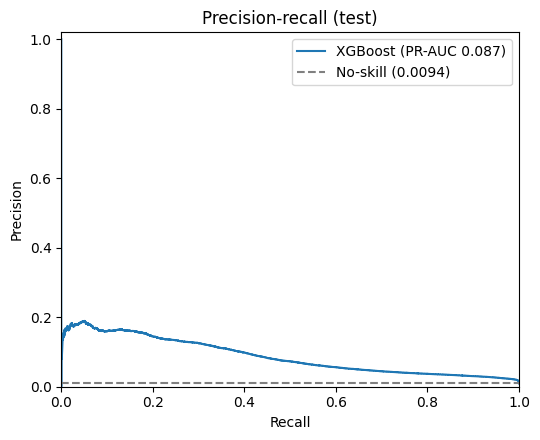

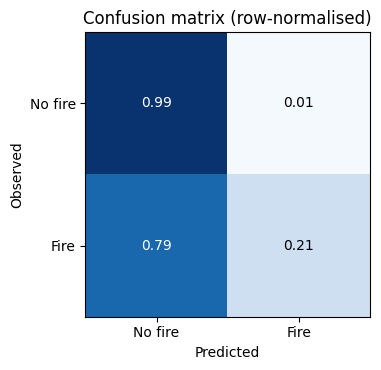

,group,pr_auc_drop_mean,pr_auc_drop_std
0,weather,0.1003,0.0002
1,terrain,0.0511,0.0024
2,vegetation,0.0134,0.0008
3,land_cover,0.0009,0.0002
4,dryness,-0.0006,0.0000


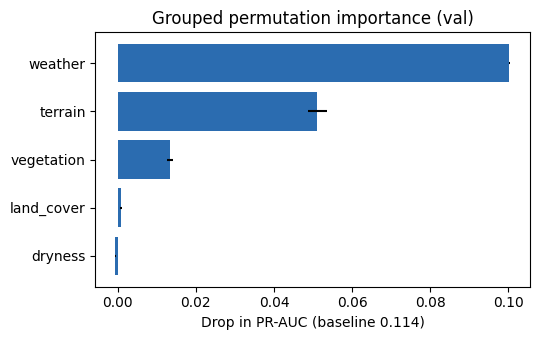

In [7]:
plot_pr({"XGBoost": (ytest, keep["p_test"])}, ytest.mean(), f"{OUT_DIR}/fig_pr_{TAG}.png")
plot_confusion(ytest, keep["p_test"], keep["thr"], f"{OUT_DIR}/fig_confusion_{TAG}.png")

base, imp = grouped_permutation_importance(keep["model"], Xval, yval, groups, n_repeats=3)
display(imp.round(4))
imp.to_csv(f"{OUT_DIR}/importance_groups_{TAG}.csv", index=False)
plot_importance(imp, base, f"{OUT_DIR}/fig_importance_{TAG}.png")

if PER_FEATURE:   # slow: one shuffle per feature
    base_f, imp_f = grouped_permutation_importance(keep["model"], Xval, yval,
                                                   {f: [f] for f in feats}, n_repeats=2, max_rows=100_000)
    display(imp_f.head(15).round(4))
    imp_f.to_csv(f"{OUT_DIR}/importance_features_{TAG}.csv", index=False)

In [8]:
json.dump(dict(tag=TAG, params={k: str(v) for k, v in XGB_PARAMS.items()}, seeds=SEEDS,
               veg_variant=VEG_VARIANT, n_features=len(feats),
               rows={k: len(v) for k, v in splits.items()}, quick_test=QUICK_TEST),
          open(f"{OUT_DIR}/config_{TAG}.json", "w"), indent=2)
if globals().get("SAVE_MODEL"):
    import joblib
    joblib.dump(keep["model"], f"{OUT_DIR}/model_{TAG}.joblib", compress=3)
print("Done. Files in", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

Done. Files in /content/drive/MyDrive/GIS_DATA/results/results_xg
   config_xgb_prev.json
   fig_confusion_xgb_prev.png
   fig_importance_xgb_prev.png
   fig_pr_xgb_prev.png
   importance_groups_xgb_prev.csv
   metrics_per_seed_xgb_prev.csv
   metrics_summary_xgb_prev.csv
   predictions_xgb_prev_test.csv
   predictions_xgb_prev_val.csv
